In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

Loading the Dataset


In [3]:
df=pd.read_csv('/content/housing_prices_regression.csv')
df

,num_bedrooms,year_built,zipcode_dup,zipcode,size_sqft,has_garage,id,has_garden,num_bathrooms,sale_price
0,2.0,2021.0,110002.0,110002.0,1075,Ys,H20000,NaN,3.0,NaN
1,3.0,1954.0,560001.0,560001.0,1482,Ye,H20001,o,1.5,293483.53
2,2.0,1991.0,560002.0,560002.0,1689,No,H20002,No,2.5,179736.91
3,3.0,1956.0,NaN,NaN,1415,Yes,H20003,es,NaN,462700.04
4,NaN,1991.0,560001.0,560001.0,1765,No,H20004,NO,1.0,272214.40
...,...,...,...,...,...,...,...,...,...,...
255,2.0,1950.0,110001.0,110001.0,1402,No,H20012,NO,2.0,NaN
256,2.0,1991.0,560002.0,560002.0,1689,No,H20002,No,2.5,179736.91
257,3.0,1954.0,560001.0,560001.0,1482,Ye,H20001,o,1.5,293483.53
258,3.0,1974.0,110003.0,110003.0,1239,YES,NaN,NaN,2.0,701046.18


Exploring the dataset


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 260 entries, 0 to 259
Data columns (total 10 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   num_bedrooms   238 non-null    float64
 1   year_built     241 non-null    float64
 2   zipcode_dup    230 non-null    float64
 3   zipcode        230 non-null    float64
 4   size_sqft      237 non-null    object 
 5   has_garage     237 non-null    object 
 6   id             230 non-null    object 
 7   has_garden     232 non-null    object 
 8   num_bathrooms  221 non-null    float64
 9   sale_price     238 non-null    float64
dtypes: float64(6), object(4)
memory usage: 20.4+ KB


In [5]:
df.head()

,num_bedrooms,year_built,zipcode_dup,zipcode,size_sqft,has_garage,id,has_garden,num_bathrooms,sale_price
0,2.0,2021.0,110002.0,110002.0,1075,Ys,H20000,NaN,3.0,NaN
1,3.0,1954.0,560001.0,560001.0,1482,Ye,H20001,o,1.5,293483.53
2,2.0,1991.0,560002.0,560002.0,1689,No,H20002,No,2.5,179736.91
3,3.0,1956.0,NaN,NaN,1415,Yes,H20003,es,NaN,462700.04
4,NaN,1991.0,560001.0,560001.0,1765,No,H20004,NO,1.0,272214.40


In [6]:
df.isnull().sum()

,0
num_bedrooms,22
year_built,19
zipcode_dup,30
zipcode,30
size_sqft,23
has_garage,23
id,30
has_garden,28
num_bathrooms,39
sale_price,22


### Check for Duplicate Rows

Let's check if there are any duplicate records in our dataset so we can keep our analysis clean.

In [8]:
# Calculate the number of duplicate rows in the entire dataframe
duplicate_rows_count = df.duplicated().sum()
print(f"Number of duplicate rows in the dataset: {duplicate_rows_count}")

Number of duplicate rows in the dataset: 10


### Explore Unique Categorical Values and Inconsistencies

Let's inspect the unique values in categorical columns like 'has_garage' and 'has_garden' to see what inconsistencies we need to clean up later.

In [9]:
# Show unique values for categorical features
print("Unique values in 'has_garage':", df['has_garage'].unique())
print("Unique values in 'has_garden':", df['has_garden'].unique())

Unique values in 'has_garage': ['Ys' 'Ye' 'No' 'Yes' 'N' nan 'YES' 'o' 'es' 'NO']
Unique values in 'has_garden': [nan 'o' 'No' 'es' 'NO' 'Yes' 'Ye' 'N' 'Ys' 'YES']


### Check Column Data Types and Values of 'size_sqft'

Let's investigate why 'size_sqft' is listed as an 'object' type instead of numerical. We will print some of its unique values.

In [10]:
# View the first 20 unique values of size_sqft to identify non-numeric characters
print(df['size_sqft'].unique()[:20])

['1075' '1482' '1689' '1415' '1765' '1177' '1901' '1549' '2118' '2466'
 '1312' '1328' '1402' '1738' '2030' '1239' '1652' '1446' '1747' '2104']


### Check Redundancy between zipcode and zipcode_dup
Let's check if 'zipcode' and 'zipcode_dup' are identical columns so we can decide whether to drop one of them during preprocessing.

In [11]:
# Compare the two zipcode columns where they are both not null
comparison = df[df['zipcode'].notnull() & df['zipcode_dup'].notnull()]
are_identical = (comparison['zipcode'] == comparison['zipcode_dup']).all()
print(f"Are 'zipcode' and 'zipcode_dup' identical where both are non-null? {are_identical}")

Are 'zipcode' and 'zipcode_dup' identical where both are non-null? True


### Drop Duplicate Rows
Let's remove duplicate records to ensure the integrity of our dataset.

In [12]:
# Remove duplicate rows in-place and verify
df.drop_duplicates(inplace=True)
print(f"Remaining rows after dropping duplicates: {len(df)}")

Remaining rows after dropping duplicates: 250


### Drop Redundant Columns
Since 'zipcode_dup' is identical to 'zipcode', we can drop it safely.

In [13]:
# Drop the redundant zipcode_dup column
if 'zipcode_dup' in df.columns:
    df.drop(columns=['zipcode_dup'], inplace=True)
print(df.columns)

Index(['num_bedrooms', 'year_built', 'zipcode', 'size_sqft', 'has_garage',
       'id', 'has_garden', 'num_bathrooms', 'sale_price'],
      dtype='object')


### Clean and Convert 'size_sqft' to Numerical
Let's convert 'size_sqft' into a numerical data type, coercing any non-numeric values to NaN so they can be processed.

In [14]:
# Convert size_sqft to numeric, setting any non-numeric text to NaN
df['size_sqft'] = pd.to_numeric(df['size_sqft'], errors='coerce')
print(df['size_sqft'].dtypes)

float64


### Standardize Categorical Values for 'has_garage' and 'has_garden'
Let's map the inconsistent values (like 'Ys', 'Ye', 'YES', 'es', 'o') to standard 'Yes' or 'No'.

In [15]:
# Define mapping dictionary for standardizing Yes/No flags
yes_no_map = {
    'Ys': 'Yes', 'Ye': 'Yes', 'Yes': 'Yes', 'YES': 'Yes', 'es': 'Yes', 'o': 'Yes',
    'No': 'No', 'NO': 'No', 'N': 'No'
}

# Standardize both columns
df['has_garage'] = df['has_garage'].map(yes_no_map)
df['has_garden'] = df['has_garden'].map(yes_no_map)

print("Cleaned has_garage unique values:", df['has_garage'].unique())
print("Cleaned has_garden unique values:", df['has_garden'].unique())

Cleaned has_garage unique values: ['Yes' 'No' nan]
Cleaned has_garden unique values: [nan 'Yes' 'No']


### Handle Missing Values (Imputation)
Let's impute missing values using simple strategies: median for numerical columns and mode (most frequent) for categorical columns.

In [16]:
# Impute numerical columns with their median
num_cols = ['num_bedrooms', 'year_built', 'zipcode', 'size_sqft', 'num_bathrooms', 'sale_price']
for col in num_cols:
    if col in df.columns:
        df[col] = df[col].fillna(df[col].median())

# Impute categorical columns with their mode
cat_cols = ['has_garage', 'has_garden']
for col in cat_cols:
    if col in df.columns:
        df[col] = df[col].fillna(df[col].mode()[0])

# Check for any remaining null values
print(df.isnull().sum())

num_bedrooms      0
year_built        0
zipcode           0
size_sqft         0
has_garage        0
id               29
has_garden        0
num_bathrooms     0
sale_price        0
dtype: int64


### Drop Identifier Column ('id')
Let's drop the 'id' column because it contains unique identifiers that do not provide any predictive capability for modeling.

In [17]:
# Drop the 'id' column and confirm there are no remaining missing values
if 'id' in df.columns:
    df.drop(columns=['id'], inplace=True)
print(df.isnull().sum())

num_bedrooms     0
year_built       0
zipcode          0
size_sqft        0
has_garage       0
has_garden       0
num_bathrooms    0
sale_price       0
dtype: int64


### Outlier Handling using IQR Method
Let's handle outliers in our main numerical columns ('size_sqft' and 'sale_price') by capping them at the 1.5 * IQR boundaries to keep our data clean and stable.

In [18]:
# Simple outlier capping using IQR for size_sqft and sale_price
for col in ['size_sqft', 'sale_price']:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    # Cap the outliers
    df[col] = np.clip(df[col], lower_bound, upper_bound)

print("Outliers successfully capped!")
display(df[['size_sqft', 'sale_price']].describe())

Outliers successfully capped!


,size_sqft,sale_price
count,250.000000,250.000000
mean,1536.299000,428863.570680
std,365.669508,206193.194766
min,592.250000,31232.910000
25%,1291.250000,251079.545000
50%,1513.000000,445861.080000
75%,1757.250000,589810.965000
max,2456.250000,799590.280000


### Univariate Analysis: Distribution of Target Variable
Let's visualize the distribution of our target variable 'sale_price' using a simple histogram and density plot.

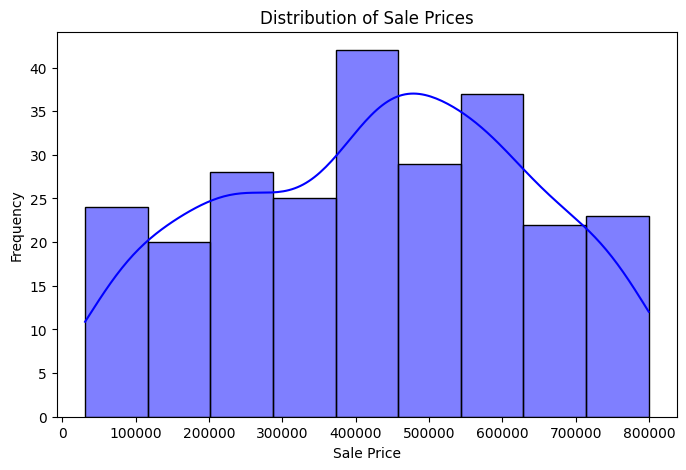

In [19]:
# Plot the distribution of housing sale prices
plt.figure(figsize=(8, 5))
sns.histplot(df['sale_price'], kde=True, color='blue')
plt.title('Distribution of Sale Prices')
plt.xlabel('Sale Price')
plt.ylabel('Frequency')
plt.show()

### Bivariate Analysis: Size vs Sale Price
Let's explore the relationship between the house size ('size_sqft') and 'sale_price' using a simple scatter plot.

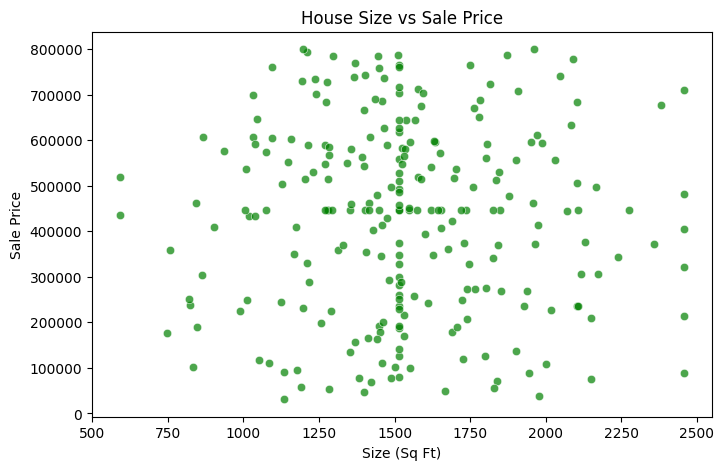

In [20]:
# Scatter plot to show relationship between size and price
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x='size_sqft', y='sale_price', alpha=0.7, color='green')
plt.title('House Size vs Sale Price')
plt.xlabel('Size (Sq Ft)')
plt.ylabel('Sale Price')
plt.show()

### Multivariate Analysis: Correlation Heatmap
Let's construct a correlation heatmap of all numerical columns to understand how variables interact with each other.

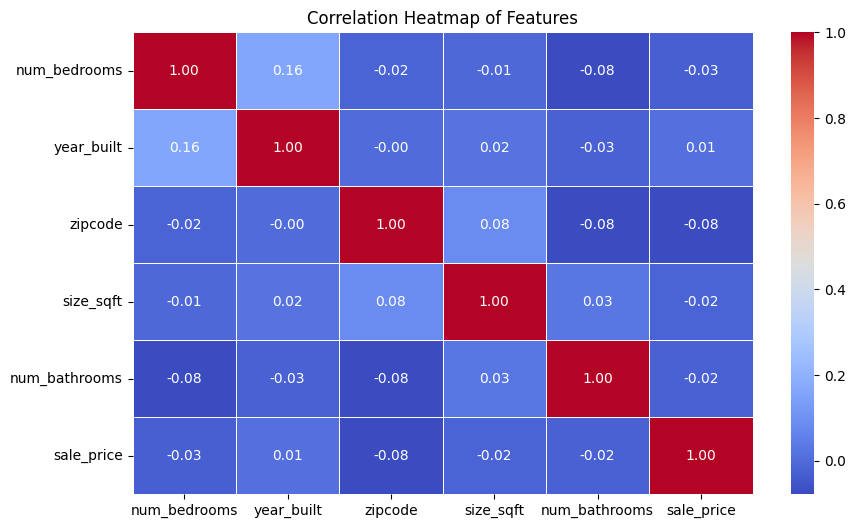

In [21]:
# Calculate and plot correlations among numeric features
plt.figure(figsize=(10, 6))
numeric_df = df.select_dtypes(include=[np.number])
sns.heatmap(numeric_df.corr(), annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Correlation Heatmap of Features')
plt.show()

### Final Data Encoding for Machine Learning
Let's convert our standardized categorical variables ('has_garage' and 'has_garden') into numerical flags (0 and 1) so that the dataset is in its final, perfectly usable form for any regression algorithms.

In [22]:
# Map categorical 'Yes'/'No' to 1/0
df['has_garage'] = df['has_garage'].map({'Yes': 1, 'No': 0})
df['has_garden'] = df['has_garden'].map({'Yes': 1, 'No': 0})

# Display the final clean head of our dataset
print("Final Preprocessed Dataset Shape:", df.shape)
display(df.head())

Final Preprocessed Dataset Shape: (250, 8)


,num_bedrooms,year_built,zipcode,size_sqft,has_garage,has_garden,num_bathrooms,sale_price
0,2.0,2021.0,110002.0,1075.0,1,1,3.0,445861.08
1,3.0,1954.0,560001.0,1482.0,1,1,1.5,293483.53
2,2.0,1991.0,560002.0,1689.0,0,0,2.5,179736.91
3,3.0,1956.0,110003.0,1415.0,1,1,2.0,462700.04
4,3.0,1991.0,560001.0,1765.0,0,0,1.0,272214.40


### Create Sequential ID and Export Preprocessed Dataset

Let's add a fresh, clean sequential 'id' column starting from 0 and save our perfectly processed dataset to a CSV file.

In [25]:
# Reset the index to create a sequential ID column starting from 0
df = df.reset_index()
df.rename(columns={'index': 'id'}, inplace=True)

# Save the preprocessed dataset to a new CSV file
df.to_csv('preprocessed_housing_prices.csv', index=False)
print('Preprocessed dataset successfully saved to preprocessed_housing_prices.csv')
display(df.head())

Preprocessed dataset successfully saved to preprocessed_housing_prices.csv


,id,num_bedrooms,year_built,zipcode,size_sqft,has_garage,has_garden,num_bathrooms,sale_price
0,0,2.0,2021.0,110002.0,1075.0,1,1,3.0,445861.08
1,1,3.0,1954.0,560001.0,1482.0,1,1,1.5,293483.53
2,2,2.0,1991.0,560002.0,1689.0,0,0,2.5,179736.91
3,3,3.0,1956.0,110003.0,1415.0,1,1,2.0,462700.04
4,4,3.0,1991.0,560001.0,1765.0,0,0,1.0,272214.40


In [23]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 250 entries, 0 to 249
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   num_bedrooms   250 non-null    float64
 1   year_built     250 non-null    float64
 2   zipcode        250 non-null    float64
 3   size_sqft      250 non-null    float64
 4   has_garage     250 non-null    int64  
 5   has_garden     250 non-null    int64  
 6   num_bathrooms  250 non-null    float64
 7   sale_price     250 non-null    float64
dtypes: float64(6), int64(2)
memory usage: 17.6 KB


In [24]:
df.head()

,num_bedrooms,year_built,zipcode,size_sqft,has_garage,has_garden,num_bathrooms,sale_price
0,2.0,2021.0,110002.0,1075.0,1,1,3.0,445861.08
1,3.0,1954.0,560001.0,1482.0,1,1,1.5,293483.53
2,2.0,1991.0,560002.0,1689.0,0,0,2.5,179736.91
3,3.0,1956.0,110003.0,1415.0,1,1,2.0,462700.04
4,3.0,1991.0,560001.0,1765.0,0,0,1.0,272214.40
